## Grupo 17:
Alicia Mei García Morín (100498828)
Ana Grima Vázquez de Prada (100495785)

El objetivo de esta práctica es construir un modelo de aprendizaje automático capaz de predecir si un cliente bancario suscribirá un depósito a plazo.
En este notebook se construye el modelo: contiene el EDA, la métrica de evaluación, los métodos básicos y avanzados, la evaluación y modelo final.

# 2. EDA Simplificado

En esta sección se realiza un análisis exploratorio básico del dataset con el objetivo de entender su estructura y preparar el posterior preprocesamiento.

## 2.1 Dimensiones del dataset

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_pickle("bank_13.pkl")
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [4]:
df.shape

(11000, 17)

El dataset contiene:
- 11000 instancias (filas) = número de clientes
- 17 atributos (columnas) = número de variables



## 2.2 Tipos de variables y de problema

In [5]:
df.dtypes

age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
deposit      object
dtype: object

In [6]:
categorical_columns = df.select_dtypes(include=["object"]).columns
numerical_columns   = df.select_dtypes(include=["int64","float64"]).columns

print("Categóricas:", list(categorical_columns))
print("Numéricas:", list(numerical_columns))

Categóricas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'deposit']
Numéricas: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']


Se identifican 10 variables categóricas (de tipo objeto):
- job
- marital
- education
- default
- housing
- loan
- contact
- month
- poutcome
- deposit

Y 7 variables numéricas (aquellas de tipo entero o flotante):
- age
- balance
- day
- duration
- campaign
- pdays
- previous

La variable objetivo es `deposit` y es categórica, por lo que se trata de un problema de clasificación binaria.

## 2.3 Cardinalidad de variables categóricas

In [7]:
categorical_columns = df.select_dtypes(include=["object"]).columns
cardinality = df[categorical_columns].nunique()
cardinality

job          12
marital       3
education     4
default       2
housing       2
loan          2
contact       3
month        12
poutcome      4
deposit       2
dtype: int64

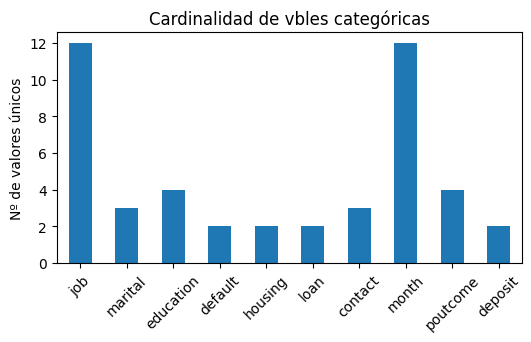

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,3))
cardinality.plot(kind="bar")
plt.title("Cardinalidad de vbles categóricas")
plt.ylabel("Nº de valores únicos")
plt.xticks(rotation=45)
plt.show()

Observamos que hay dos variables con alta cardinalidad (más de 10 valores únicos): `job` y `month` con 12 categorías.

Estas variables se tratarán en el preprocesamiento usando variables dummy.

## 2.4 Valores ausentes

In [9]:
print("How many missing values per attribute:")
print("======================================")
print(df.isnull().sum())

How many missing values per attribute:
age            0
job            0
marital      406
education      0
default        0
balance        0
housing        0
loan           0
contact        0
day            0
month          0
duration       0
campaign       0
pdays          0
previous       0
poutcome       0
deposit        0
dtype: int64


In [10]:
missing_values = df.isnull().sum()
print("\nVariables con missing values:")
print(missing_values[missing_values > 0])


Variables con missing values:
marital    406
dtype: int64


Se observan valores faltantes únicamente en la variable `marital`, con un total de 406 valores nulos.

El resto de variables no presentan valores faltantes.

Dado que `marital` es una variable categórica, estos valores deberán tratarse durante el preprocesamiento mediante técnicas de imputación apropiadas.

## 2.5 Columnas constantes o tipo ID

In [11]:
constant_cols = [col for col in df.columns if df[col].nunique() == 1]
print("Columnas constantes:", constant_cols)

id_cols = [col for col in df.columns if df[col].nunique() == len(df)]
print("Columnas tipo ID:", id_cols)

Columnas constantes: []
Columnas tipo ID: []


No se observan columnas constantes o columnas de ID

# 2.6 Desbalanceo

In [12]:
print("Distribución absoluta de la variable objetivo:")
print("===============================================")
print(df["deposit"].value_counts())

print("\nDistribución porcentual:")
print("========================")
print(df["deposit"].value_counts(normalize=True))

Distribución absoluta de la variable objetivo:
deposit
no     5780
yes    5220
Name: count, dtype: int64

Distribución porcentual:
deposit
no     0.525455
yes    0.474545
Name: proportion, dtype: float64


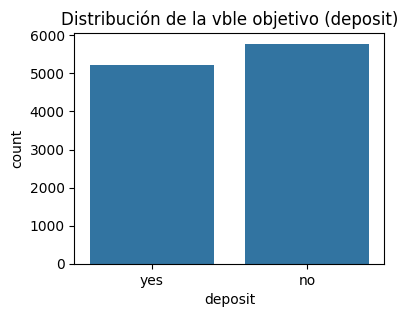

In [13]:
plt.figure(figsize=(4,3))
sns.countplot(x="deposit", data=df)
plt.title("Distribución de la vble objetivo (deposit)")
plt.show()

In [14]:
df['deposit'].value_counts(normalize=True)

deposit
no     0.525455
yes    0.474545
Name: proportion, dtype: float64

La variable `deposit` indica si el cliente suscribió un depósito. Como hemos visto en puntos anteriores, se trata de un problema de clasificación binaria.
La distribución de clases es:

- 52.55% para la clase "no"
- 47.45% para la clase "yes"

Por tanto, el dataset no tiene un desbalanceo significativo. Como se observa en la gráfica, la variable objetivo presenta una distribución relativamente equilibrada entre ambas clases.

## 2.7 Análisis de las variables numéricas


In [15]:
df[numerical_columns].describe()

,age,balance,day,duration,campaign,pdays,previous
count,11000.000000,11000.000000,11000.000000,11000.000000,11000.00000,11000.000000,11000.000000
mean,41.252727,1529.139273,15.660818,372.524909,2.50800,51.308636,0.828000
std,11.940474,3217.396248,8.417970,347.515713,2.72221,108.782842,2.282936
min,18.000000,-6847.000000,1.000000,2.000000,1.00000,-1.000000,0.000000
25%,32.000000,122.750000,8.000000,138.000000,1.00000,-1.000000,0.000000
50%,39.000000,549.500000,15.000000,255.000000,2.00000,-1.000000,0.000000
75%,49.000000,1711.000000,22.000000,498.000000,3.00000,20.250000,1.000000
max,95.000000,81204.000000,31.000000,3881.000000,63.00000,854.000000,58.000000


Observamos de nuevo que no existen valores ausentes en las variables numéricas, ya que todas las tienen 11.000 valores.

La variable `age` presenta valores entre 18 y 95 años, lo cual es lo normal.

La variable `balance` tiene valores que van desde -6847 hasta 81204. Esto indicaría que hay clientes con deudas y otros con balances muy altos.

La variable `duration` también presenta una gran dispersión (std ≈ 347) y un máximo bastante elevado (3881 segundos), seguramente algunas llamadas fueron muy largas.

En el caso de `campaign`, aunque la media es baja (≈2.5 contactos), el valor máximo alcanza 63, lo que indica que algunos clientes fueron contactados muchas veces.

La variable `pdays` requiere que la analicemos en profundiad, ya que observamos valores mínimos de -1.

Por último, la variable `previous` muestra que la mayoría de los clientes no habían sido contactados anteriormente (mediana = 0), aunque existen algunos casos con valores elevados (hasta 58 contactos previos).

In [16]:
print("\nValores más frecuentes de pdays:")
print("===============================")
print(df["pdays"].value_counts().head(15))

n_minus1 = (df["pdays"] == -1).sum()
print("\nPorcentaje de -1 en pdays:", round(100*n_minus1/len(df), 2), "%")


Valores más frecuentes de pdays:
pdays
-1      8203
 92      105
 182      88
 91       82
 181      79
 183      73
 184      51
 94       42
 93       40
 95       37
 87       34
 90       32
 98       31
 185      30
 187      28
Name: count, dtype: int64

Porcentaje de -1 en pdays: 74.57 %


La variable `pdays` representa el número de días transcurridos desde el último contacto en una campaña anterior.

Observamos que el valor -1 aparece 8203 veces, lo que es el 74.57% del dataset. El -1 no representa un número real de días, sino ausencia de contacto previo. Lo que indica que una gran parte de los clientes no fueron contactados previamente.

Por tanto, el valor -1 no debe interpretarse como un valor numérico válido, lo trataremos en el preprocesamiento.


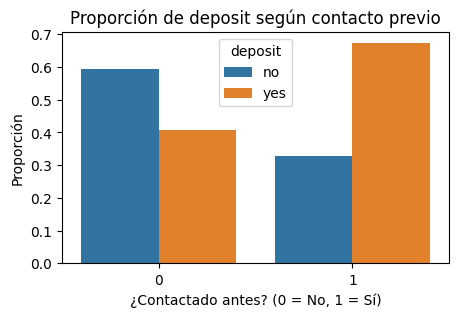

In [17]:
df_tmp = df.copy()
df_tmp["contacted_before"] = (df_tmp["pdays"] != -1).astype(int)

prop = (
    df_tmp.groupby("contacted_before")["deposit"]
    .value_counts(normalize=True)
    .rename("proportion")
    .reset_index()
)

plt.figure(figsize=(5,3))
sns.barplot(x="contacted_before", y="proportion", hue="deposit", data=prop)

plt.title("Proporción de deposit según contacto previo")
plt.xlabel("¿Contactado antes? (0 = No, 1 = Sí)")
plt.ylabel("Proporción")
plt.show()

Hemos analizado si `pdays` realemente influye en la probabilidad de contratar el depósito. Observamos que la proporción de clientes que contratan el depósito es diferente entre ambos grupos, lo que indica que la variable `pdays` (o el hecho de haber sido contactado antes) contiene información relevante para el modelo.

Según los fundamentos de preprocesamiento vistos en clase, ante valores que no representan información numérica real, pueden aplicarse distintas estrategias como:
- Tratarlos como valores ausentes e imputarlos.
- Transformar el atributo generando nuevas variables que capturen mejor la información relevante.
- Discretizar el atributo en rangos.
- Eliminar la variable si no aporta información significativa.

Como el 74.57% de los valores son -1, hemos pensado que la mejor opción será crear una nueva variable binaria *contacted_before*, que indique si el cliente fue contactado previamente o no. Además de reemplazar el valor -1 por NaN, para que pueda ser tratado adecuadamente en el pipeline de preprocesamiento.

In [18]:
df["contacted_before"] = (df["pdays"] != -1).astype(int)

df["pdays"] = df["pdays"].replace(-1, pd.NA)

print("Missing en pdays:", df["pdays"].isnull().sum())
print("Distribución contacted_before:\n", df["contacted_before"].value_counts())

Missing en pdays: 8203
Distribución contacted_before:
 contacted_before
0    8203
1    2797
Name: count, dtype: int64


## 2.8 Conclusiones del EDA


El dataset contiene 11.000 instancias y 17 atributos. Encontramos variables numéricas (`age, balance, day, duration, campaign, pdays, previous`) y categóricas (`job, marital, education, default, housing, loan, contact, month, poutcome`), donde `deposit` es nuestra variable objetivo.

No existen columnas constantes o de ID.

Únicamente tiene valores faltantes  la variable `marital` (406 valores), que deberán imputarse durante el preprocesamiento.

Existen variables categóricas con alta cardinalidad (`job` y `month`), que necesitarán codificación mediante variables dummy.

El problema es de clasificación binaria y el conjunto presenta un desbalanceo leve entre clases (52.55% frente a 47.45%).

Por último, la variable `pdays` presenta el valor -1 en el 74.57% de los casos, indicando ausencia de contacto previo. Dado que este valor no representa un número real de días, se ha decidido crear la variable binaria *contacted_before* y tratar los valores -1 como ausentes, permitiendo así un tratamiento más adecuado en el pipeline de preprocesamiento.



# 3. Decisiones de evaluación

En esta sección se define la estrategia de evaluación del modelo, incluyendo la partición de los datos, la métrica seleccionada y el procedimiento de validación que se utilizará para estimar el rendimiento del modelo.

## 3.1 Evaluación outer

Se fija una semilla basada en el NIA del grupo para garantizar la reproducibilidad de los resultados.

In [19]:
SEED = 100498828

La estimación del rendimiento futuro se realizará mediante Holdout, dividiendo el conjunto de datos en train (2/3) y test (1/3).
Al tratarse de un problema de clasificación binaria con datos bastante balanceados (52.55% frente a 47.45%), decidimos usar la métrica Accuracy como medida principal de evaluación, que calcula la proporción total de aciertos.
El conjunto de test se usa únicamente al final de la práctica para estimar el rendimiento futuro del modelo seleccionado, evitando así problemas de data leakage.

Tras el EDA, el dataset incluye la nueva variable `contacted_before`, creada a partir de `pdays` para capturar si el cliente fue contactado previamente. Esta variable se incorpora como atributo adicional en el conjunto de entrada \(X\).

In [20]:
from sklearn.model_selection import train_test_split
X = df.drop(columns=["deposit"])
y = df["deposit"]
print("Features (X):", X.shape)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=1/3,
    stratify=y,
    random_state=SEED
)
print("Train size:", X_train.shape)
print("Test size:", X_test.shape)

Features (X): (11000, 17)
Train size: (7333, 17)
Test size: (3667, 17)


## 3.2 Evaluación inner

Para comparar modelos y optimizar los hiperparámetros, decidimos usar la validación cruzada estratificada de 5 particiones (Stratified 5-fold Cross Validation), ya que consideramos que es más óptima para un equilibrio entre coste y estabilidad de la estimación. En esta, el conjunto de entrenamiento se divide en 5 subconjuntos y en cada iteración, el modelo se entrena utilizando 4 de los subconjuntos (80% del train), evaluándose en el subconjunto restante (20%).

Este proceso se repite 5 veces, de modo que cada subconjunto actúa una vez como conjunto de validación.

Respecto al número de particiones, consideramos otras alternativas:

•	10-fold cross validation sería más estable, pero duplica el coste computacional.

•	Leave-One-Out Cross Validation (LOOCV) sería demasiado costoso en esta práctica (11.000 entrenamientos por modelo).

•	Repeated Holdout también podría utilizarse, pero puede producir solapamientos entre particiones y resultados menos consistentes.


Se ha optado por validación cruzada frente a un simple holdout interno porque nos ha parecido más estable, ya que este último depende demasiado de una única partición de los datos.

In [21]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

# 4. Métodos básicos: KNN y Trees

En esta sección se evaluarán dos métodos básicos de aprendizaje automático: K-Nearest Neighbors (KNN) y Árboles de Decisión. 

En primer lugar, se utilizará KNN para determinar el preprocesamiento más adecuado para el problema, comparando distintos métodos de escalado (MinMaxScaler, StandardScaler y RobustScaler) y de imputación de valores faltantes (media y mediana). 

Una vez seleccionado el mejor preprocesamiento, se evaluarán ambos modelos (KNN y Árboles de Decisión) utilizando sus hiperparámetros por defecto. Posteriormente, se realizará el ajuste de los hiperparámetros más relevantes de cada método mediante técnicas de optimización, analizando además el efecto de dichos hiperparámetros sobre el rendimiento de los modelos.

## 4.1 Selección de escalado e imputación (KNN)


Para determinar el preprocesamiento más adecuado para el problema, utilizamos K-Nearest Neighbors (KNN) como modelo base y construimos distintos pipelines que combinan métodos de imputación y escalado. 

En concreto, se consideran dos métodos de imputación para las variables numéricas (media y mediana) y tres métodos de escalado (StandardScaler, MinMaxScaler y RobustScaler). Las variables categóricas se imputan mediante la moda y posteriormente se codifican mediante One-Hot Encoding. Cada combinación se evalúa utilizando los hiperparámetros por defecto de KNN y validación cruzada estratificada sobre el conjunto de entrenamiento.

El objetivo de este proceso es seleccionar el preprocesamiento que produzca el mejor rendimiento para utilizarlo posteriormente en el resto de modelos de esta sección.

In [51]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold

df = pd.read_pickle("bank_13.pkl")

df["contacted_before"] = (df["pdays"] != -1).astype(int)

df["pdays"] = df["pdays"].replace(-1, np.nan)

X = df.drop(columns=["deposit"])
y = df["deposit"].map({"no": 0, "yes": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=1/3,
    stratify=y,
    random_state=SEED
)

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

print(X_train.shape, X_test.shape)
print(X_train["pdays"].isna().sum())
print(type(X_train["pdays"].iloc[0]))

(7333, 17) (3667, 17)
5444
<class 'numpy.float64'>


In [52]:
import time
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

categorical_cols = X_train.select_dtypes(include=["object"]).columns.tolist()
numerical_cols   = X_train.select_dtypes(include=["int64","float64"]).columns.tolist()

imputers = ["mean", "median"]
scalers = [StandardScaler(), MinMaxScaler(), RobustScaler()]

results = []
for imputer_strategy in imputers:
    for scaler in scalers:
        numeric_transformer = Pipeline([
            ("imputer", SimpleImputer(strategy=imputer_strategy)),
            ("scaler", scaler),
        ])
        categorical_transformer = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ])
        preprocessor = ColumnTransformer(
            transformers=[
                ("num", numeric_transformer, numerical_cols),
                ("cat", categorical_transformer, categorical_cols),
            ],
            remainder="drop",
        )

        pipe = Pipeline([
            ("preprocessor", preprocessor),
            ("clf", KNeighborsClassifier()),
        ])

        t0 = time.time()
        scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)
        elapsed = time.time() - t0

        results.append({
            "imputer": imputer_strategy,
            "scaler": scaler.__class__.__name__,
            "mean_accuracy": np.mean(scores),
            "std_accuracy": np.std(scores),
            "cv_time_s": elapsed,
        })

results_df = pd.DataFrame(results).sort_values("mean_accuracy", ascending=False).reset_index(drop=True)
results_df

,imputer,scaler,mean_accuracy,std_accuracy,cv_time_s
0,mean,StandardScaler,0.799673,0.003771,0.087197
1,median,StandardScaler,0.799537,0.003910,0.087579
2,mean,RobustScaler,0.775535,0.002256,0.087010
3,median,RobustScaler,0.775126,0.003321,0.097245
4,mean,MinMaxScaler,0.728216,0.005359,0.099464
5,median,MinMaxScaler,0.728216,0.005359,0.087653


Los resultados muestran que la combinación formada por imputación mediante la **media** y escalado mediante **StandardScaler** obtiene el mejor rendimiento medio en validación cruzada (accuracy ≈ 0.80). La imputación mediante la mediana con el mismo escalado presenta un rendimiento prácticamente equivalente, mientras que los métodos de escalado RobustScaler y MinMaxScaler ofrecen resultados claramente inferiores.

Por tanto, se selecciona la combinación **imputación por la media + StandardScaler** como estrategia de preprocesamiento para los modelos que se evaluarán en los siguientes apartados.

## 4.2 Evaluación con hiperparámetros por defecto

In [53]:
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
import numpy as np
import time

### Dummy classifier

Como referencia inicial se evalúa un modelo Dummy que siempre predice la clase mayoritaria del conjunto de datos. Este modelo no utiliza ninguna información de las variables de entrada y sirve como baseline para comprobar que los modelos reales ofrecen un rendimiento superior a una estrategia trivial.

In [54]:
model = DummyClassifier(strategy="most_frequent")

start = time.time()
scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
end = time.time()

print("Dummy accuracy:", scores.mean())
print("Training time:", end-start)

Dummy accuracy: 0.5254329565777157
Training time: 0.007544994354248047


Como referencia inicial se evalúa un modelo Dummy que siempre predice la clase mayoritaria. Este modelo obtiene una accuracy media de aproximadamente **0.525**, lo que coincide con la proporción de la clase mayoritaria en el dataset.

Este valor se utiliza como baseline para comprobar que los modelos reales aportan capacidad predictiva superior a una estrategia trivial.

### KNN

Para evaluar KNN es necesario aplicar previamente el preprocesamiento seleccionado en el apartado anterior. Para ello se utiliza un Pipeline que integra tanto el preprocesamiento (imputación, escalado y codificación de variables categóricas) como el propio modelo.

El uso de Pipeline garantiza que todas las transformaciones se ajusten únicamente sobre los datos de entrenamiento dentro de cada partición de la validación cruzada, evitando así posibles problemas de data leakage.

In [55]:
categorical_cols = X_train.select_dtypes(include=["object"]).columns.tolist()
numerical_cols   = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler()),
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_cols),
        ("cat", categorical_transformer, categorical_cols),
    ],
    remainder="drop",
)

knn_default = Pipeline([
    ("preprocessor", preprocessor),
    ("clf", KNeighborsClassifier())
])

start = time.time()
scores = cross_val_score(knn_default, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)
end = time.time()

print("KNN accuracy:", scores.mean())
print("KNN std:", scores.std())
print("Training time:", end - start)

KNN accuracy: 0.799673225583681
KNN std: 0.0037714651741077064
Training time: 0.08702516555786133


Utilizando el preprocesamiento seleccionado en el apartado anterior (imputación por la media y escalado mediante StandardScaler para las variables numéricas, junto con imputación por la moda y One-Hot Encoding para las categóricas), el modelo KNN con hiperparámetros por defecto obtiene una accuracy media de **0.7997** en validación cruzada.

Este resultado mejora claramente al modelo Dummy, lo que indica que KNN es capaz de capturar información predictiva relevante en el conjunto de datos. Además, la desviación estándar es reducida (**0.0038**), lo que sugiere un comportamiento estable entre particiones.

### Árbol de decisión con hiperparámetros por defecto

Para evaluar el árbol de decisión con hiperparámetros por defecto, se construye un Pipeline que integra el preprocesamiento necesario para tratar los valores faltantes y las variables categóricas. A diferencia de KNN, el árbol no requiere escalado de las variables numéricas, por lo que únicamente se aplica imputación en las variables numéricas e imputación por la moda junto con One-Hot Encoding en las categóricas.

In [56]:
categorical_cols = X_train.select_dtypes(include=["object"]).columns.tolist()
numerical_cols   = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()

numeric_transformer_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="mean"))
])

categorical_transformer_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor_tree = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_tree, numerical_cols),
        ("cat", categorical_transformer_tree, categorical_cols),
    ],
    remainder="drop",
)

tree_default = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("clf", DecisionTreeClassifier(random_state=SEED))
])

start = time.time()
scores = cross_val_score(tree_default, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)
end = time.time()

print("Tree accuracy:", scores.mean())
print("Tree std:", scores.std())
print("Training time:", end - start)

Tree accuracy: 0.7852176134645785
Tree std: 0.00803593711784143
Training time: 0.09821939468383789


El árbol de decisión con hiperparámetros por defecto obtiene una accuracy media de **0.785** en validación cruzada, superando claramente al modelo Dummy pero quedando ligeramente por debajo del rendimiento obtenido con KNN.

La desviación estándar es algo mayor que en el caso de KNN, lo que indica una mayor variabilidad del modelo entre las distintas particiones de entrenamiento. No obstante, el tiempo de entrenamiento es considerablemente menor, lo que muestra que los árboles de decisión son modelos más rápidos de entrenar.

En conjunto, el árbol de decisión ofrece un buen equilibrio entre rendimiento y coste computacional, aunque en este caso KNN obtiene una ligera mejora en accuracy.

## 4.3 Árboles poco profundos e interpretación

Para analizar la interpretabilidad del modelo, entrenamos un árbol de decisión con profundidad limitada. Los árboles poco profundos permiten visualizar fácilmente las reglas de decisión y entender qué variables influyen más en la predicción.

En este apartado se entrena un árbol con profundidad máxima reducida y se visualiza su estructura para interpretar las principales decisiones del modelo.

In [57]:
from sklearn.tree import DecisionTreeClassifier

tree_shallow = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("clf", DecisionTreeClassifier(max_depth=3, random_state=SEED))
])

tree_shallow.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers cont

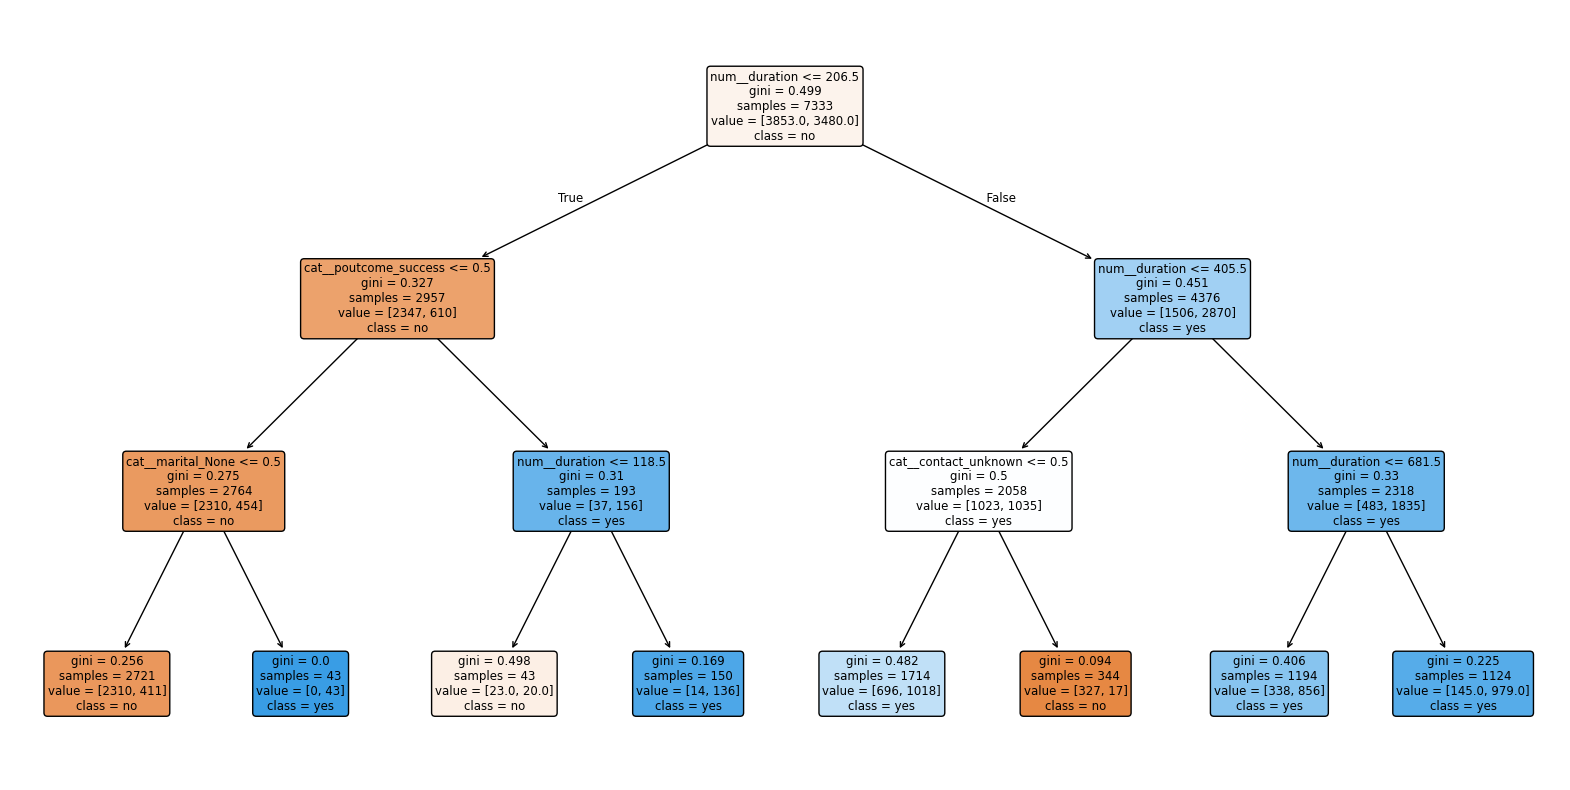

In [58]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

feature_names = tree_shallow.named_steps["preprocessor"].get_feature_names_out()

plt.figure(figsize=(20,10))
plot_tree(
    tree_shallow.named_steps["clf"],
    feature_names=feature_names,
    class_names=["no", "yes"],
    filled=True,
    rounded=True,
    max_depth=3
)
plt.show()

El árbol poco profundo permite identificar las variables más relevantes para la predicción. En la raíz del árbol aparece la variable **duration**, lo que indica que la duración de la llamada es el factor más influyente en la probabilidad de que un cliente suscriba un depósito.

En general, llamadas más largas se asocian con una mayor probabilidad de contratación, mientras que llamadas cortas tienden a terminar en una respuesta negativa.

Además, variables como **poutcome** (resultado de campañas anteriores) y **contact** también aparecen en niveles superiores del árbol, lo que sugiere que la información sobre contactos previos con el cliente es relevante para la decisión final.

Este tipo de árboles poco profundos resulta especialmente útil para interpretar el comportamiento del modelo y entender qué factores influyen en la decisión de contratación.

## 4.4 Ajuste de hiperparámetros

Tras evaluar los modelos con sus hiperparámetros por defecto, procedemos a optimizar su configuración mediante búsqueda de hiperparámetros.

Para ello utilizamos **GridSearchCV**, que permite evaluar distintas combinaciones de parámetros utilizando validación cruzada sobre el conjunto de entrenamiento. Este procedimiento se aplica sobre pipelines completos que incluyen tanto el preprocesamiento como el modelo, evitando así problemas de data leakage.

En este apartado se optimizan los hiperparámetros de **KNN** y **Decision Tree**, con el objetivo de encontrar la configuración que proporcione el mejor rendimiento en validación cruzada.

### Ajuste con hiperparámetros para KNN

El ajuste de hiperparámetros mediante GridSearchCV muestra que la mejor configuración para KNN corresponde a **5 vecinos**, distancia **euclídea** (`p = 2`) y ponderación por **distance**. Con esta configuración se obtiene una accuracy media de **0.8002** en validación cruzada.

La mejora respecto al modelo con hiperparámetros por defecto es pequeña, lo que indica que la configuración estándar de KNN ya era razonablemente adecuada para este problema. Aun así, se utilizará esta configuración optimizada en los siguientes análisis.

In [59]:
from sklearn.model_selection import GridSearchCV

knn_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("clf", KNeighborsClassifier())
])

param_grid_knn = {
    "clf__n_neighbors": [3,5,7,9,11,15],
    "clf__weights": ["uniform","distance"],
    "clf__p": [1,2]
}

grid_knn = GridSearchCV(
    knn_pipe,
    param_grid_knn,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

grid_knn.fit(X_train, y_train)

print("Best params:", grid_knn.best_params_)
print("Best CV accuracy:", grid_knn.best_score_)

Best params: {'clf__n_neighbors': 5, 'clf__p': 2, 'clf__weights': 'distance'}
Best CV accuracy: 0.8002188908859056


### Ajuste de hiperparámetros para Decision Tree

La optimización de hiperparámetros mediante GridSearchCV indica que la mejor configuración para el árbol de decisión corresponde a una **profundidad máxima de 10**, con **min_samples_split = 2** y **min_samples_leaf = 1**. 

Con esta configuración el modelo alcanza una accuracy media de **0.8151** en validación cruzada, lo que supone una mejora clara respecto al árbol con hiperparámetros por defecto. 

Este resultado sugiere que permitir una mayor profundidad en el árbol aumenta su capacidad para capturar relaciones más complejas entre las variables, mejorando así el rendimiento del modelo.

In [60]:
tree_pipe = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("clf", DecisionTreeClassifier(random_state=SEED))
])

param_grid_tree = {
    "clf__max_depth": [3,5,7,10,None],
    "clf__min_samples_split": [2,5,10],
    "clf__min_samples_leaf": [1,2,5]
}

grid_tree = GridSearchCV(
    tree_pipe,
    param_grid_tree,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

grid_tree.fit(X_train, y_train)

print("Best params:", grid_tree.best_params_)
print("Best CV accuracy:", grid_tree.best_score_)

Best params: {'clf__max_depth': 10, 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 2}
Best CV accuracy: 0.8150838914381534


El ajuste de hiperparámetros mediante GridSearchCV permite mejorar el rendimiento de ambos modelos respecto a sus configuraciones por defecto. En el caso de KNN, la mejor combinación corresponde a **n_neighbors = 5**, **p = 2** (distancia euclídea) y **weights = 'distance'**, obteniendo una accuracy media de aproximadamente **0.8002** en validación cruzada. La mejora respecto al modelo por defecto es pequeña, lo que indica que los parámetros iniciales ya ofrecían un buen rendimiento.

Por otro lado, el ajuste del **árbol de decisión** muestra una mejora más notable, alcanzando una accuracy media de **0.8151** con **max_depth = 10**, **min_samples_split = 2** y **min_samples_leaf = 1**. Esto sugiere que permitir una mayor profundidad en el árbol mejora su capacidad para capturar relaciones más complejas en los datos.

En conjunto, el **árbol de decisión optimizado obtiene el mejor rendimiento entre los modelos evaluados**, superando tanto al KNN optimizado como a las versiones con hiperparámetros por defecto.

## 4.5 Análisis gráfico del efecto de hiperparámetros

Para analizar cómo influyen los hiperparámetros en el rendimiento de los modelos, se representan gráficamente las variaciones de la accuracy media en validación cruzada al modificar algunos de los parámetros más relevantes.

En el caso de KNN se analiza el efecto del número de vecinos (`n_neighbors`), mientras que para el árbol de decisión se estudia el impacto de la profundidad máxima del árbol (`max_depth`).

### Gráfico para KNN (n_neighbors)

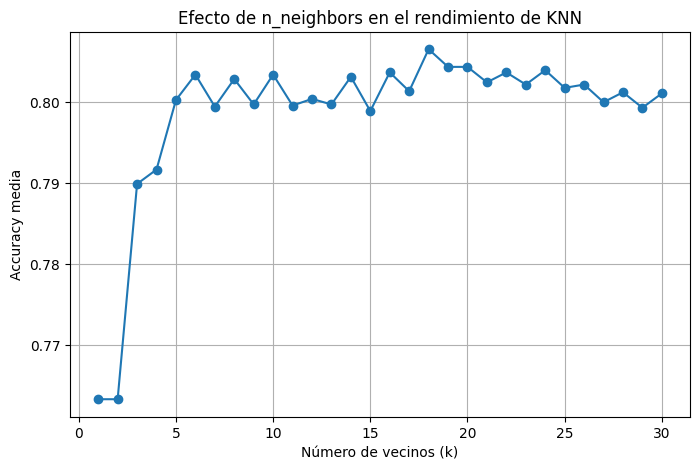

In [63]:
neighbors = range(1, 31)
scores = []

for k in neighbors:
    
    knn_model = Pipeline([
        ("preprocessor", preprocessor),
        ("clf", KNeighborsClassifier(
            n_neighbors=k,
            weights="distance",
            p=2
        ))
    ])
    
    score = cross_val_score(
        knn_model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )
    
    scores.append(score.mean())

plt.figure(figsize=(8,5))
plt.plot(neighbors, scores, marker="o")
plt.xlabel("Número de vecinos (k)")
plt.ylabel("Accuracy media")
plt.title("Efecto de n_neighbors en el rendimiento de KNN")
plt.grid(True)
plt.show()

### Gráfico para Decision Tree (max_depth)

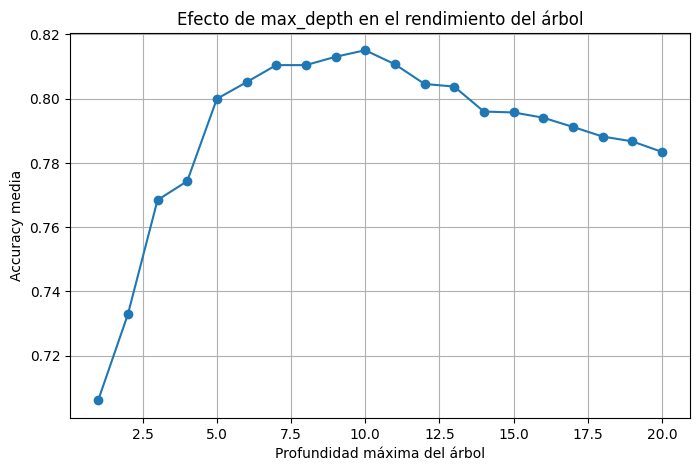

In [62]:
depths = range(1, 21)
scores_tree = []

for d in depths:
    
    tree_model = Pipeline([
        ("preprocessor", preprocessor_tree),
        ("clf", DecisionTreeClassifier(
            max_depth=d,
            min_samples_split=2,
            min_samples_leaf=1,
            random_state=SEED
        ))
    ])
    
    score = cross_val_score(
        tree_model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )
    
    scores_tree.append(score.mean())

plt.figure(figsize=(8,5))
plt.plot(depths, scores_tree, marker="o")
plt.xlabel("Profundidad máxima del árbol")
plt.ylabel("Accuracy media")
plt.title("Efecto de max_depth en el rendimiento del árbol")
plt.grid(True)
plt.show()

El análisis gráfico muestra cómo influyen los hiperparámetros en el rendimiento de los modelos. En el caso de KNN, la accuracy aumenta rápidamente al incrementar el número de vecinos desde valores muy pequeños y se estabiliza aproximadamente a partir de **k ≈ 5**, manteniéndose en torno a 0.80 para valores mayores.

En el árbol de decisión, el rendimiento mejora al aumentar la profundidad máxima hasta aproximadamente **max_depth ≈ 10**, donde se alcanza la mayor accuracy. A partir de ese punto el rendimiento comienza a disminuir ligeramente, lo que puede indicar un mayor riesgo de sobreajuste.

Estos resultados son consistentes con los hiperparámetros obtenidos en el proceso de optimización, confirmando que **k = 5** para KNN y **max_depth = 10** para el árbol de decisión ofrecen el mejor equilibrio entre complejidad del modelo y capacidad predictiva.

## 4.6 Conclusiones

En esta sección se han evaluado dos modelos base de clasificación: **K-Nearest Neighbors (KNN)** y **Árboles de Decisión**. En primer lugar, se seleccionó el preprocesamiento más adecuado mediante la comparación de distintas combinaciones de imputación y escalado, observándose que **StandardScaler junto con imputación por media o mediana ofrece el mejor rendimiento para KNN**.

Posteriormente, se evaluaron ambos modelos con sus hiperparámetros por defecto, comprobando que **KNN obtiene una accuracy cercana a 0.80**, mientras que el **árbol de decisión alcanza aproximadamente 0.79**. El análisis de un árbol poco profundo permitió además interpretar algunas de las variables más relevantes del problema.

A continuación, se realizó el **ajuste de hiperparámetros mediante GridSearchCV**, lo que permitió mejorar el rendimiento de ambos modelos. En el caso de **KNN**, la mejor configuración se obtiene con **k = 5**, distancia euclídea y ponderación por distancia, alcanzando una accuracy de aproximadamente **0.80**. Para el **árbol de decisión**, la mejor configuración corresponde a **max_depth = 10**, logrando una accuracy de **0.815**, superior a la obtenida con KNN.

Finalmente, el análisis gráfico del efecto de los hiperparámetros confirma estos resultados, mostrando que el rendimiento de KNN se estabiliza a partir de valores moderados de k y que el árbol alcanza su mejor comportamiento con una profundidad intermedia.

En conjunto, los resultados indican que **el árbol de decisión optimizado es el modelo que obtiene el mejor rendimiento en el conjunto de entrenamiento**, por lo que se perfila como el candidato más prometedor para la evaluación final.